# Expected Threat: fitting and action valuation

**Analytical question:** Value locations and completed movement.

**Stages in this notebook:** Action counts; reward; transition matrix; iterative solution; endpoint gain.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

**Example controls:** edit the example-selection cell near the top and rerun. Exploration and animation code is inline; no downloaded videos or separate HTML export is required.

## 1. Imports and data location

## Reading the code

Each statement performs one step. Names describe the values being calculated, and comments explain the purpose or units. A `for` loop repeats the indented steps for each player, frame or example. A function groups steps that we reuse later.

`pandas` tables hold the data. Square brackets select columns or rows; a condition such as `distance < 2` creates a True/False filter. `NumPy` arrays hold numbers for the calculations. `axis=0` refers to rows and `axis=1` to columns in a two-dimensional array. Shape comments explain additional dimensions where needed.

Run the worked calculations in order before using the final exploration section. The plotting and file-loading functions are included here so the notebook runs on its own.

Use `and` to combine individual True/False values. Use `&` to combine whole pandas columns of conditions. `np.hypot(dx, dy)` calculates distance from horizontal and vertical differences. `np.column_stack` joins columns, while `np.concatenate` joins existing arrays.

In [1]:
from pathlib import Path
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT_items_1 = []
for p in candidates:
    if (p / "data/1925299/1925299_match.json").exists():
        ROOT_items_1.append(p)
if len(ROOT_items_1) > 0:
    ROOT = ROOT_items_1[0]
else:
    ROOT = Path.cwd()
DATA_ROOT = ROOT / "data/1925299"


## Choose an example with selection variables

First run the notebook top to bottom. For another example, change these variables, run this selection cell, then rerun the final exploration cell. Refit models only when you intend to. Near the end, `available_possessions` and `available_events` list available choices; use their displayed identifiers. You can inspect more rows with `display(available_possessions)` or `display(available_events)`. A frame override takes priority over a possession or event. Method-specific selectors are documented in the comments.

The final explorer computes its overlays directly from real tracking frames and the method functions in this notebook. Animation frames are rendered inline using Matplotlib; no MP4 or other movie is downloaded. Missing coverage stops the clip rather than interpolating motion. The saved notebook contains a playable default animation, but choosing another example requires rerunning Python. All helpers remain inline.

In [2]:
# Example selection: change a selection, then rerun the cells below. None uses the worked default.
PERIOD = 1
FRAME_ID = None  # exact raw tracking frame; overrides event/possession start
POSSESSION_INDEX = None  # possession_index from available_possessions near the end
EVENT_ID = None  # actual supplied event_id from available_events, not row number
PLAYER_ID = None  # player_id (string or integer), from metadata
TEAM_ID = None  # team_id; None uses the initial possession team
DURATION_S = 6.0  # maximum; clips stop at coverage/selection boundaries
FRAME_STRIDE = 3  # use 1 for every 10 Hz frame; 3 gives a faster preview

# Licensed external DataBallPy 0.7.2 fitted grid, embedded for standalone use.
# SHA256: 5579f29389f27af1f22ad2922e1c03a9490b12854ce0e9d363b0dbe71af1cbbc
# https://github.com/Alek050/databallpy (MIT); this is not fitted on the sample.
# Cache the licensed fitted model as data; this is not a video or Python helper.
XT_MODEL_PATH = ROOT / "data" / "databallpy_open_play_xT.npy"
XT_MODEL_URL = "https://raw.githubusercontent.com/zcochran27/tracking-data-applied-workshop/d7eee179fcf4c37cdfa0d4bf5ff4806c0bd476de/resources/models/open_play_xT.npy"
if not XT_MODEL_PATH.exists():
    XT_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(XT_MODEL_URL, XT_MODEL_PATH)
XT_GRID = np.load(XT_MODEL_PATH)


## 2. Inline ingestion and plotting helpers

In [3]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True, exist_ok=True)
    revision = "4340d274572876239c154c90bc507a9b3250a656"
    base = f"https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/"
    for suffix in ["match.json", "dynamic_events.csv", "phases_of_play.csv"]:
        name = "1925299_" + suffix
        target = destination / name
        if not target.exists():
            with urllib.request.urlopen(base + name, timeout=90) as response:
                target.write_bytes(response.read())
    name = "1925299_tracking_extrapolated.jsonl"
    target = destination / name
    if not target.exists():
        url = (
            base.replace(
                "raw.githubusercontent.com/", "media.githubusercontent.com/media/"
            )
            + name
        )
        temporary = destination / (name + ".partial")
        with urllib.request.urlopen(url, timeout=90) as response, temporary.open(
            "wb"
        ) as output:
            count = 0
            for line in response:
                if line.strip():
                    json.loads(line)
                    output.write(line)
                    count += 1
                if count >= 9000:
                    break
        temporary.replace(target)


def read_tracking(destination):
    """Load the sample and make one table row for each player in each frame."""
    dataset = skillcorner.load(
        meta_data=destination / "1925299_match.json",
        raw_data=destination / "1925299_tracking_extrapolated.jsonl",
        coordinates="skillcorner",
    )
    wide = dataset.to_df()
    metadata_file = destination / "1925299_match.json"
    metadata = json.loads(metadata_file.read_text(encoding="utf-8"))

    # Each line in the tracking file is one JSON record.
    raw_records = []
    tracking_file = destination / "1925299_tracking_extrapolated.jsonl"
    for line in tracking_file.read_text().splitlines():
        if line.strip():
            raw_records.append(json.loads(line))

    # Dictionaries let us look up a value using a frame or player identifier.
    player_possession = {}
    visibility = {}
    for record in raw_records:
        frame_number = record["frame"]
        possession = record.get("possession", {})
        (player_possession[frame_number]) = str(possession.get("player_id"))
        for player in record.get("player_data", []):
            player_id = str(player["player_id"])
            (visibility[frame_number, player_id]) = player.get("is_detected")

    player_tables = []
    for player in metadata["players"]:
        player_id = str(player["id"])
        x_column = player_id + "_x"
        y_column = player_id + "_y"
        if x_column not in wide.columns:
            continue
        columns = [
            "period_id",
            "frame_id",
            "timestamp",
            "ball_owning_team_id",
            x_column,
            y_column,
        ]
        player_table = wide[columns].copy()
        player_table.columns = [
            "period_id",
            "frame_id",
            "timestamp",
            "team_in_possession",
            "x",
            "y",
        ]
        (player_table["player_id"]) = player_id
        (player_table["team_id"]) = player["team_id"]
        (player_table["name"]) = player["short_name"]
        player_tables.append(player_table)

    tracking = pd.concat(player_tables, ignore_index=True)
    (tracking["seconds"]) = tracking["timestamp"].dt.total_seconds()
    (tracking["player_in_possession"]) = tracking["frame_id"].map(player_possession)
    detection_flags = []
    for row in tracking.itertuples():
        detection_flags.append(visibility.get((row.frame_id, row.player_id)))
    (tracking["is_detected"]) = detection_flags
    tracking = tracking.sort_values(["player_id", "period_id", "frame_id"])
    return dataset, wide, tracking, metadata, raw_records


def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5.5))
    ax.set_facecolor("#eef3ed")
    ax.add_patch(Rectangle((-52.5, -34), 105, 68, fill=False, color="#597063"))
    ax.plot([0, 0], [-34, 34], c="#597063")
    ax.add_patch(Circle((0, 0), 9.15, fill=False, color="#597063"))
    for x in [-52.5, 36]:
        ax.add_patch(Rectangle((x, -20.16), 16.5, 40.32, fill=False, color="#597063"))
    ax.set(
        xlim=(-55, 55), ylim=(-36, 36), aspect="equal", xlabel="x (m)", ylabel="y (m)"
    )
    return ax


## 3. Read the real sample

In [4]:
ensure_sample(DATA_ROOT)
dataset, wide, tracking, metadata, raw = read_tracking(DATA_ROOT)
events = pd.read_csv(DATA_ROOT / "1925299_dynamic_events.csv")
phases = pd.read_csv(DATA_ROOT / "1925299_phases_of_play.csv")
observed = tracking.dropna(subset=["x", "y"])
complete = observed.groupby(["period_id", "frame_id"]).size()
if FRAME_ID is not None:
    frame_id = int(FRAME_ID)
else:
    frame_id = int(complete[complete == 22].index[20][1])
snapshot = observed[observed.frame_id == frame_id].copy()
keepers = set()
for p in metadata["players"]:
    if "goalkeeper" in p["player_role"]["name"].lower():
        keepers.add(str(p["id"]))
role_labels = {}
for p in metadata["players"]:
    (role_labels[str(p["id"])]) = p["player_role"]["acronym"]
assert not tracking.duplicated(["period_id", "frame_id", "player_id"]).any()
display(
    tracking[["period_id", "frame_id", "player_id", "x", "y", "is_detected"]].head(3)
)
print("Real bounded sample. Diagnostic frame:", frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Define labeled actions and states

Start with a transparent synthetic two-state corpus so every count can be checked by hand.

In [5]:
actions = pd.DataFrame(
    [
        dict(start=0, end=1, kind="move", success=True, goal=False),
        dict(start=0, end=1, kind="move", success=False, goal=False),
        dict(start=1, end=1, kind="shot", success=False, goal=True),
        dict(start=1, end=1, kind="shot", success=False, goal=False),
    ]
)
display(actions)


,start,end,kind,success,goal
0,0,1,move,True,False
1,0,1,move,False,False
2,1,1,shot,False,True
3,1,1,shot,False,False


## 5. Estimate rewards and successful transitions

Divide counts by all attempted actions from each state. Failed movement has zero continuation in this formulation.

,action_count,immediate_goal_reward
0,2.0,0.0
1,2.0,0.5


,0,1
0,0.0,0.5
1,0.0,0.0


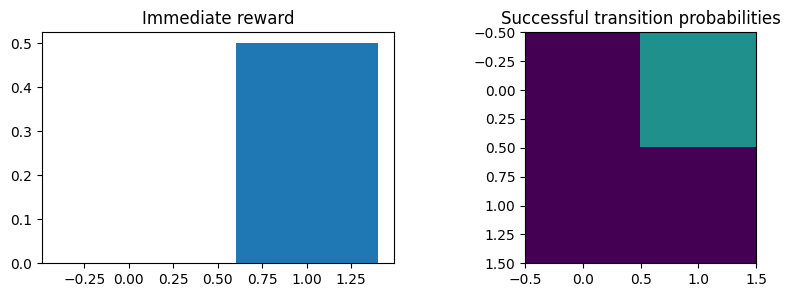

In [6]:
def estimate_xt_components(actions, n_states):
    """Count actions, goals and successful moves before converting them to rates."""
    totals = np.zeros(n_states)
    goal_counts = np.zeros(n_states)
    move_counts = np.zeros((n_states, n_states))
    for action in actions.itertuples():
        start_state = action.start
        (totals[start_state]) += 1
        if action.kind == "shot":
            (goal_counts[start_state]) += float(action.goal)
        elif action.success:
            end_state = int(action.end)
            (move_counts[start_state, end_state]) += 1

    reward = np.zeros(n_states)
    transition = np.zeros((n_states, n_states))
    for state in range(n_states):
        # Use 1 for an empty state to avoid dividing by zero; its counts remain zero.
        action_count = max(totals[state], 1)
        (reward[state]) = goal_counts[state] / action_count
        (transition[state]) = move_counts[state] / action_count
    return totals, reward, transition


totals, reward, transition = estimate_xt_components(actions, 2)
display(pd.DataFrame({"action_count": totals, "immediate_goal_reward": reward}))
display(pd.DataFrame(transition))
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].bar(range(2), reward)
axs[0].set_title("Immediate reward")
axs[1].imshow(transition, vmin=0, vmax=1)
axs[1].set_title("Successful transition probabilities")
plt.show()


## 6. Inspect value propagation

Follow the iteration from zero values through reward and continuation.

,state 0,state 1
iteration,,
0,0.00,0.0
1,0.00,0.5
2,0.25,0.5
3,0.25,0.5
4,0.25,0.5
5,0.25,0.5
6,0.25,0.5
7,0.25,0.5
8,0.25,0.5


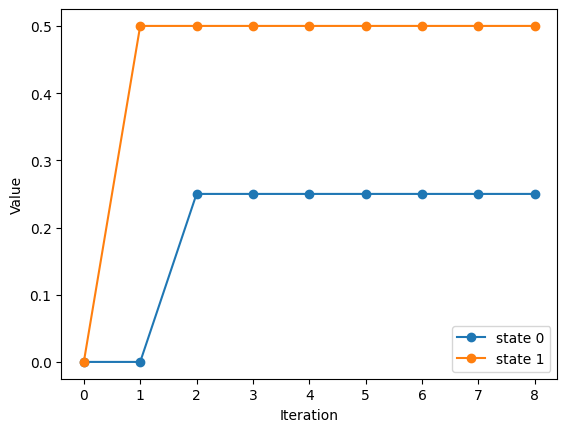

In [7]:
def xt_iterations(transition, reward, steps=8):
    value = np.zeros(len(reward))
    history = [value.copy()]
    for _ in range(steps):
        continuation = transition @ value
        value = reward + continuation
        history.append(value.copy())
    return np.array(history)


history = xt_iterations(transition, reward)
display(pd.DataFrame(history, columns=["state 0", "state 1"]).rename_axis("iteration"))
plt.plot(history, "o-")
plt.xlabel("Iteration")
plt.ylabel("Value")
plt.legend(["state 0", "state 1"])
plt.show()


## 7. Solve to convergence

Package the inspected components and update equation into a reusable fitter.

In [8]:
def fit_xt(actions, n_states, tolerance=1e-10, max_iter=10000):
    totals, reward, transition = estimate_xt_components(actions, n_states)
    value = np.zeros(n_states)
    for _ in range(max_iter):
        new = reward + transition @ value
        if np.max(np.abs(new - value)) < tolerance:
            return new, transition, reward
        value = new
    raise ValueError("No convergence; inspect termination and recurrent states")


values, transition, reward = fit_xt(actions, 2)
assert np.allclose(values, [0.25, 0.5])
display(pd.Series(values, name="Fitted synthetic xT"))


0    0.25
1    0.50
Name: Fitted synthetic xT, dtype: float64

## 8. Final output: completed-action value gain

Use the values just fitted rather than introducing a separate arbitrary value table.

,start_state,end_state,start_value,end_value,gain
0,0,1,0.25,0.50,0.25
1,1,0,0.50,0.25,-0.25


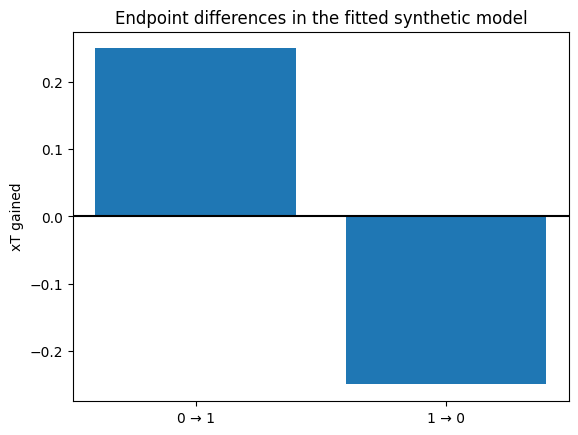

In [9]:
def endpoint_gain(values, start, end):
    return np.asarray(values)[end] - np.asarray(values)[start]


start = np.array([0, 1])
end = np.array([1, 0])
gains = endpoint_gain(values, start, end)
display(
    pd.DataFrame(
        {
            "start_state": start,
            "end_state": end,
            "start_value": values[start],
            "end_value": values[end],
            "gain": gains,
        }
    )
)
plt.bar(["0 → 1", "1 → 0"], gains)
plt.axhline(0, c="black")
plt.ylabel("xT gained")
plt.title("Endpoint differences in the fitted synthetic model")
plt.show()


## Explore different examples

Run this after the method calculations above. After the first complete run, edit and run the selection cell near the top, then rerun this exploration cell to analyze another example. The worked intermediate steps stay visible above; this section applies the method again to your selection.

,possession_index,period,start_frame,end_frame,team_id,duration_s
0,0,1,10,39,NaN,3.0
1,1,1,40,306,1802.0,26.7
2,2,1,307,347,871.0,4.1
3,3,1,348,371,1802.0,2.4
4,4,1,372,573,871.0,20.2
5,5,1,574,586,1802.0,1.3
6,6,1,587,592,NaN,0.6
7,7,1,593,598,871.0,0.6
8,8,1,599,784,NaN,18.6
9,9,1,973,987,871.0,1.5


,event_id,event_type,frame_start,frame_end
0,8_0,player_possession,39,39
1,1_0,off_ball_run,43,67
2,8_1,player_possession,57,57
3,7_0,passing_option,57,57
4,8_2,player_possession,89,94
5,7_1,passing_option,89,94
6,7_2,passing_option,91,94
7,9_0,on_ball_engagement,134,143
8,9_1,on_ball_engagement,135,143
9,8_3,player_possession,143,143


,event_id,frame_end,x_end,y_end,player_targeted_x_reception,player_targeted_y_reception
0,8_0,39,0.32,-0.30,-9.61,-0.48
4,8_2,94,-35.63,20.93,-22.57,20.90
12,8_4,186,-2.18,-22.21,-11.25,-3.91
16,8_5,211,-12.28,-1.21,-6.72,17.42
20,8_6,241,-5.84,19.08,5.49,19.19
26,8_7,259,2.55,18.22,-4.98,15.22
36,8_9,281,-14.81,-23.68,-4.83,-25.27
38,8_10,342,19.03,-27.23,24.11,-10.34
52,8_11,367,28.25,-12.11,21.59,-16.05
58,8_12,385,22.76,-16.23,38.30,-28.82


Recomputed overlays on 20 real frames; first/last: (1, 34) (1, 91)


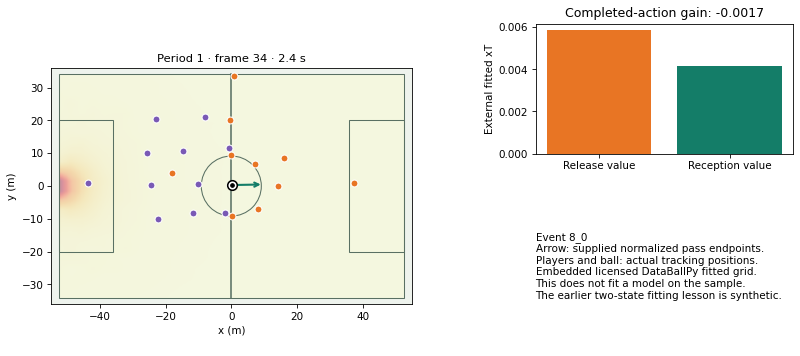

In [10]:
method_name = "xt"
# All animation inputs and method calculations are local tracking data, not a video asset.
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Polygon, Wedge
from IPython.display import HTML, display

players_by_id = {}
for player in metadata["players"]:
    (players_by_id[str(player["id"])]) = player
home_team_id = int(metadata["home_team"]["id"])
away_team_id = int(metadata["away_team"]["id"])
tracking_records = list(raw)
if method_name == "graph_epv":
    unique_records_by_key = {}
    for record in raw + goal_sequence:
        if record.get("period") is not None:
            (unique_records_by_key[int(record["period"]), int(record["frame"])]) = (
                record
            )
    tracking_records = list(unique_records_by_key.values())
source_frames = {}
for record in tracking_records:
    if record.get("period") is not None:
        (source_frames[int(record["period"]), int(record["frame"])]) = record
frames_by_key = {}
for frame_key, record in source_frames.items():
    position_flags = []
    for player in record["player_data"]:
        position_flags.append(
            player.get("x") is not None and player.get("y") is not None
        )
    if (
        frame_key[0] == PERIOD
        and len(record.get("player_data", [])) == 22
        and all(position_flags)
        and (record.get("ball_data", {}).get("x") is not None)
        and (record["ball_data"].get("y") is not None)
        and (record.get("timestamp") is not None)
    ):
        (frames_by_key[frame_key]) = record
assert frames_by_key, "No complete frames for PERIOD in the cached source."


def tracking_time(record):
    return pd.to_timedelta(record["timestamp"]).total_seconds()


def possession_team(record):
    """Translate the source's team label into the corresponding team identifier."""
    group = record.get("possession", {}).get("group")
    if group == "home team":
        return home_team_id
    if group == "away team":
        return away_team_id
    return None


def attack_direction(team, period):
    """Return -1 for attacks to the left and +1 for attacks to the right."""
    home_attacks_left = metadata["home_team_side"][period - 1] == "right_to_left"
    if team == home_team_id:
        attacks_left = home_attacks_left
    else:
        attacks_left = not home_attacks_left
    if attacks_left:
        return -1
    return 1


def players_at_frame(frame_key):
    """Make a player table and estimate velocity using the immediately previous frame."""
    record = frames_by_key[frame_key]
    period, frame_number = frame_key
    previous_record = source_frames.get((period, frame_number - 1))
    previous_players = {}
    elapsed_seconds = np.nan
    if previous_record is not None:
        for player in previous_record.get("player_data", []):
            (previous_players[str(player["player_id"])]) = player
        if previous_record.get("timestamp"):
            elapsed_seconds = tracking_time(record) - tracking_time(previous_record)

    player_rows = []
    for player in record["player_data"]:
        player_id = str(player["player_id"])
        previous_player = previous_players.get(player_id, {})
        velocity = np.array([np.nan, np.nan])
        valid_time = 0.05 <= elapsed_seconds <= 0.15
        has_previous_x = previous_player.get("x") is not None
        has_previous_y = previous_player.get("y") is not None
        if valid_time and has_previous_x and has_previous_y:
            current_position = np.array([player["x"], player["y"]])
            previous_position = np.array([previous_player["x"], previous_player["y"]])
            velocity = (current_position - previous_position) / elapsed_seconds
        player_rows.append(
            {
                "player_id": player_id,
                "team_id": int(players_by_id[player_id]["team_id"]),
                "x": player["x"],
                "y": player["y"],
                "vx": velocity[0],
                "vy": velocity[1],
                "is_detected": player.get("is_detected"),
            }
        )
    return pd.DataFrame(player_rows)


def draw_tracking_frame(axis, frame_key):
    tracking_record = frames_by_key[frame_key]
    player_table = players_at_frame(frame_key)
    pitch(axis)
    for team_id, color in [(home_team_id, "#e87524"), (away_team_id, "#7959b5")]:
        team_players = player_table[player_table.team_id == team_id]
        axis.scatter(
            team_players.x, team_players.y, c=color, edgecolors="white", s=44, zorder=5
        )
    ball_position = np.array(
        [tracking_record["ball_data"]["x"], tracking_record["ball_data"]["y"]]
    )
    axis.scatter(*ball_position, s=85, c="white", edgecolors="black", lw=1.5, zorder=10)
    axis.scatter(*ball_position, s=12, c="black", zorder=11)
    axis.set_title(
        f"Period {frame_key[0]} · frame {frame_key[1]} · {tracking_time(tracking_record):.1f} s",
        fontsize=11,
    )
    return player_table, ball_position, tracking_record


# Possessions here are uninterrupted supplied team-possession spans, not inferred player control.
example_catalog = []
previous = None
group = None
for frame_key in sorted(frames_by_key):
    record = frames_by_key[frame_key]
    current_possession_team = possession_team(record)
    continuous = (
        previous is not None
        and frame_key[1] == previous[1] + 1
        and 0 < tracking_time(record) - tracking_time(frames_by_key[previous]) <= 0.15
    )
    if not continuous or current_possession_team != group:
        example_catalog.append(
            dict(
                possession_index=len(example_catalog),
                period=frame_key[0],
                start_frame=frame_key[1],
                end_frame=frame_key[1],
                team_id=current_possession_team,
            )
        )
    else:
        (example_catalog[-1]["end_frame"]) = frame_key[1]
    previous = frame_key
    group = current_possession_team
available_possessions = pd.DataFrame(example_catalog)
(available_possessions["duration_s"]) = (
    available_possessions.end_frame - available_possessions.start_frame + 1
) / 10
if "events" in globals():
    available_events_items_1 = []
    for k in frames_by_key:
        available_events_items_1.append(k[1])
    available_events = events[
        (events.period == PERIOD) & events.frame_start.isin(available_events_items_1)
    ].copy()
else:
    available_events = pd.DataFrame()
display(available_possessions.head(10))
if len(available_events):
    display(
        available_events[["event_id", "event_type", "frame_start", "frame_end"]].head(
            10
        )
    )

clip_start_frame = None
clip_stop_frame = None
example_action = None
if method_name == "formation":
    available_windows = timeline[timeline.period == PERIOD].copy()
    display(available_windows.head(12))
    if FORMATION_WINDOW not in set(available_windows.window):
        raise ValueError(
            "FORMATION_WINDOW must be a qualifying window in available_windows."
        )
    example_window_data = team_data[
        (team_data.period_id == PERIOD)
        & (team_data.window == FORMATION_WINDOW)
        & (team_data.team_in_possession == 871)
    ]
    example_med = example_window_data.groupby("player_id")[["cx", "cy"]].median()
    example_points = -example_med.to_numpy()
    example_fits = []
    for name, t in templates.items():
        cost = ((example_points[:, None] - t[None]) ** 2).sum(2)
        rr, cc = linear_sum_assignment(cost)
        example_fits.append((name, float(np.sqrt(cost[rr, cc].mean())), cc))

    def assignment_error(fit):
        return fit[1]

    example_fits.sort(key=assignment_error)
    example_best = example_fits[0]
    candidates = []
    for k in frames_by_key:
        if (
            FORMATION_WINDOW * 30
            <= tracking_time(frames_by_key[k])
            < (FORMATION_WINDOW + 1) * 30
        ):
            candidates.append(k[1])
    assert candidates, "Selected formation window has no complete animation frames."
    clip_start_frame = min(candidates)
    clip_stop_frame = max(candidates)
elif method_name == "events":
    display(passes.reset_index(names="pass_index").head(12))
    if len(passes):
        assert 0 <= PASS_INDEX < len(passes), "PASS_INDEX is a row number in passes."
        example_action = passes.iloc[PASS_INDEX]
        clip_start_frame = max(int(example_action.release) - 8, 0)
        clip_stop_frame = int(example_action.reception) + 12
elif method_name == "xt":
    example_actions_items_1 = []
    for k in frames_by_key:
        example_actions_items_1.append(k[1])
    example_actions = (
        events[
            (events.event_type == "player_possession")
            & (events.end_type == "pass")
            & (events.pass_outcome == "successful")
            & (events.period == PERIOD)
            & events.frame_end.isin(example_actions_items_1)
        ]
        .dropna(
            subset=[
                "x_end",
                "y_end",
                "player_targeted_x_reception",
                "player_targeted_y_reception",
            ]
        )
        .copy()
    )
    display(
        example_actions[
            [
                "event_id",
                "frame_end",
                "x_end",
                "y_end",
                "player_targeted_x_reception",
                "player_targeted_y_reception",
            ]
        ].head(12)
    )
    assert len(example_actions), "No completed actions with endpoint coverage."
    if EVENT_ID is None:
        example_action = example_actions.iloc[0]
    else:
        example_action = example_actions[example_actions.event_id == EVENT_ID].iloc[0]
    clip_start_frame = int(example_action.frame_end) - 5
elif method_name == "graph_epv" and SEQUENCE == "goal":
    clip_start_frame = int(goal_sequence[0]["frame"])
    clip_stop_frame = int(goal_sequence[-1]["frame"])
elif method_name == "graph_epv" and SEQUENCE == "non_goal":
    clip_start_frame = int(non_goal_sequence[0]["frame"])
    clip_stop_frame = int(non_goal_sequence[-1]["frame"])

if EVENT_ID is not None and method_name != "xt":
    chosen = available_events[available_events.event_id == EVENT_ID]
    assert (
        len(chosen) == 1
    ), "Choose EVENT_ID from available_events.event_id, not a row number."
    clip_start_frame = int(chosen.frame_start.iloc[0])
    clip_stop_frame = int(chosen.frame_end.iloc[0]) + 10
if POSSESSION_INDEX is not None:
    chosen = available_possessions[
        available_possessions.possession_index == POSSESSION_INDEX
    ]
    assert len(chosen) == 1, "Choose POSSESSION_INDEX from available_possessions."
    clip_start_frame = int(chosen.start_frame.iloc[0])
    clip_stop_frame = int(chosen.end_frame.iloc[0])
if FRAME_ID is not None:
    clip_start_frame = int(FRAME_ID)
    clip_stop_frame = None
if clip_start_frame is None:
    clip_start_frame = int(frame_id)
if (PERIOD, clip_start_frame) not in frames_by_key:
    # An event can start on a missing frame. Move forward only within its own interval.
    possible = []
    for k in sorted(frames_by_key):
        if k[1] >= clip_start_frame and (
            clip_stop_frame is None or k[1] <= clip_stop_frame
        ):
            possible.append(k[1])
    assert possible, "No covered frame for this selection."
    clip_start_frame = possible[0]
clip_keys = []
for f in range(clip_start_frame, clip_start_frame + max(2, int(DURATION_S * 10))):
    frame_key = (PERIOD, f)
    if frame_key not in frames_by_key or (
        clip_stop_frame is not None and f > clip_stop_frame
    ):
        break
    if (
        clip_keys
        and not 0
        < tracking_time(frames_by_key[frame_key])
        - tracking_time(frames_by_key[clip_keys[-1]])
        <= 0.15
    ):
        break
    clip_keys.append(frame_key)
assert (
    len(clip_keys) >= 2
), "Selection ends at a coverage boundary; choose another covered start."
assert FRAME_STRIDE >= 1
clip_keys = clip_keys[::FRAME_STRIDE]
assert len(clip_keys) >= 2, "Reduce FRAME_STRIDE or increase clip duration."
if TEAM_ID is not None:
    selected_team = TEAM_ID
else:
    selected_team = possession_team(frames_by_key[clip_keys[0]]) or home_team_id
if PLAYER_ID is not None:
    focus_player_id = str(PLAYER_ID)
else:
    focus_player_id_items_1 = []
    for player in metadata["players"]:
        if int(player["team_id"]) == selected_team:
            focus_player_id_items_1.append(player["id"])
    if len(focus_player_id_items_1) > 0:
        focus_player_id_first_match_2 = focus_player_id_items_1[0]
    else:
        raise ValueError(
            "No matching item was found. Check the available data or your selection."
        )
    focus_player_id = str(focus_player_id_first_match_2)
if method_name == "physical" and PLAYER_ID is None:
    focus_player_id = str(
        summary.sort_values("sprint_m", ascending=False).player_id.iloc[0]
    )
example_origin = tracking_time(frames_by_key[clip_keys[0]])
example_trace_keys = clip_keys


def example_xt_value(x, y):
    ix = np.clip(int((x + 52.5) / 105 * XT_GRID.shape[0]), 0, XT_GRID.shape[0] - 1)
    iy = np.clip(int((y + 34) / 68 * XT_GRID.shape[1]), 0, XT_GRID.shape[1] - 1)
    return float(XT_GRID[ix, iy])


example_action_team = int(example_action.team_id)
example_action_sign = attack_direction(example_action_team, PERIOD)
example_xt_start = np.array([example_action.x_end, example_action.y_end])
example_xt_end = np.array(
    [
        example_action.player_targeted_x_reception,
        example_action.player_targeted_y_reception,
    ]
)
example_xt_gain = example_xt_value(*example_xt_end) - example_xt_value(
    *example_xt_start
)


def draw_method_overlay(frame_key, pitch_axis, detail_axis, summary_axis):
    for plot_axis in [pitch_axis, detail_axis, summary_axis]:
        plot_axis.clear()
    player_table, ball_position, tracking_record = draw_tracking_frame(
        pitch_axis, frame_key
    )
    clip_seconds = tracking_time(tracking_record) - example_origin
    summary_axis.axis("off")
    sign = example_action_sign
    if sign > 0:
        surface = XT_GRID.T
    else:
        surface = XT_GRID.T[::-1, ::-1]
    pitch_axis.imshow(
        surface,
        origin="lower",
        extent=(-52.5, 52.5, -34, 34),
        cmap="YlOrRd",
        alpha=0.4,
        zorder=0,
    )
    pitch_axis.annotate(
        "",
        xy=sign * example_xt_end,
        xytext=sign * example_xt_start,
        arrowprops={"arrowstyle": "->", "color": "#147d68", "lw": 2},
    )
    detail_axis.bar(
        ["Release value", "Reception value"],
        [example_xt_value(*example_xt_start), example_xt_value(*example_xt_end)],
        color=["#e87524", "#147d68"],
    )
    detail_axis.set(
        ylabel="External fitted xT",
        title=f"Completed-action gain: {example_xt_gain:+.4f}",
    )
    summary_axis.text(
        0,
        0.9,
        f"Event {example_action.event_id}\nArrow: supplied normalized pass endpoints.\nPlayers and ball: actual tracking positions.\nEmbedded licensed DataBallPy fitted grid.\nThis does not fit a model on the sample.\nThe earlier two-state fitting lesson is synthetic.",
        va="top",
        fontsize=10,
    )


def make_example_figure(frame_key):
    figure = plt.figure(figsize=(11, 5.7), dpi=75)
    layout = figure.add_gridspec(2, 2, width_ratios=[1.4, 1], hspace=0.5)
    pitch_axis = figure.add_subplot(layout[:, 0])
    detail_axis = figure.add_subplot(layout[0, 1])
    summary_axis = figure.add_subplot(layout[1, 1])
    draw_method_overlay(frame_key, pitch_axis, detail_axis, summary_axis)
    figure.subplots_adjust(
        left=0.07, right=0.97, bottom=0.14, top=0.9, wspace=0.4, hspace=0.65
    )
    return figure, (pitch_axis, detail_axis, summary_axis)


# Check two distinct frames before rendering. Animation never interpolates tracking gaps.
for example_check_key in [clip_keys[0], clip_keys[-1]]:
    example_check_figure, _ = make_example_figure(example_check_key)
    plt.close(example_check_figure)
print(
    "Recomputed overlays on",
    len(clip_keys),
    "real frames; first/last:",
    clip_keys[0],
    clip_keys[-1],
)
example_static, _ = make_example_figure(clip_keys[0])
plt.show()
example_fig, example_axes = make_example_figure(clip_keys[0])


def update_animation(i):
    draw_method_overlay(clip_keys[i], *example_axes)


animation = FuncAnimation(
    example_fig,
    update_animation,
    frames=len(clip_keys),
    interval=100 * FRAME_STRIDE,
    repeat=False,
    blit=False,
)
plt.close(example_fig)
display(HTML(animation.to_jshtml(fps=10 / FRAME_STRIDE, default_mode="once")))


## Interpretation and limitations

This synthetic corpus explains fitting mechanics. A real xT grid needs a complete action corpus, reviewed action conventions and attack normalization. Location-only xT omits defender context. [Karun Singh](https://karun.in/blog/expected-threat.html).